# Matching trial-site growers to customer records

On-farm trial sites arrive as a spreadsheet typed up by field staff: a grower name, maybe an address,
county and state, and usually GPS coordinates of the trial field. To connect each trial with the grower's purchase
history, every row has to be linked to a record in the customer master table. **There is no shared ID**, and
the names rarely match exactly. "Bob Larson" in the spreadsheet is "ROBERT LARSON" or "LARSON FARMS LLC" in the
customer table, possibly in the next county over.

The approach:

1. Clean and standardize names and addresses.
2. Score every trial-customer pair on **name similarity**, **address similarity**, and **distance**.
3. Rank the candidates for each trial site and keep the best one, unless even the best is too weak.

> **About the data.** The original ran in PySpark against a production customer table with thousands of real
> growers. Every name, address, and coordinate here is **simulated**. Because the simulation knows the true
> match, this version can also measure how accurate the matching is.

In [1]:
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from rapidfuzz import fuzz

pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

STATES_URL = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_state_20m.zip"
COUNTIES_URL = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_20m.zip"
REGION = ["IA", "MN", "NE", "SD", "WI", "IL"]

states = gpd.read_file(STATES_URL)
states = states[states.STUSPS.isin(REGION)].to_crs(4326)
counties = gpd.read_file(COUNTIES_URL)
counties = counties[counties.STUSPS.isin(REGION)].to_crs(4326)

## 1. Simulated customers and trial sites

The customer table has 1,500 growers: individuals plus farm businesses like "LARSON FARMS LLC" or
"NELSON LAND & CATTLE CO". There are 120 trial sites. 100 belong to customers, entered the messy way people
actually type: nicknames, dropped "LLC", typos, spelled-out street suffixes, missing addresses. Trial
coordinates are the trial *field*, which can be several miles from the grower's mailing address. The other
20 trial sites are growers who aren't customers at all, and the matcher should leave those unmatched.

In [2]:
rng = np.random.default_rng(7)

FIRST = {"Robert": "Bob", "William": "Bill", "James": "Jim", "Richard": "Rick", "Thomas": "Tom",
         "Michael": "Mike", "David": "Dave", "Daniel": "Dan", "Steven": "Steve", "Joseph": "Joe",
         "Charles": "Chuck", "Matthew": "Matt", "Andrew": "Andy", "Jennifer": "Jen", "Kenneth": "Ken",
         "Mark": None, "Paul": None, "Brian": None, "Kevin": None, "Eric": None, "Laura": None,
         "Susan": None, "Karen": None, "Gary": None, "Dale": None, "Wayne": None}
LAST = ["Schmidt", "Miller", "Johnson", "Anderson", "Peterson", "Olson", "Larson", "Nelson", "Meyer",
        "Hansen", "Wagner", "Becker", "Schultz", "Hoffman", "Weber", "Fischer", "Jensen", "Brandt",
        "Vogel", "Hartman", "Zimmerman", "Klein", "Bauer", "Richter", "Kuhn", "Lindgren", "Dahl",
        "Sorensen", "Halverson", "Thorson", "Engstrom", "Bergman", "Lund", "Hanson", "Kramer", "Ostrom"]
BUSINESS = ["{L} FARMS LLC", "{L} LAND & CATTLE CO", "{L} FAMILY FARMS", "{L} BROTHERS", "{L} & SONS"]


def random_points(n, polys):
    """Uniform random points inside a set of polygons (rejection sampling)."""
    shape = polys.union_all()
    minx, miny, maxx, maxy = shape.bounds
    pts = []
    while len(pts) < n:
        cand = gpd.points_from_xy(rng.uniform(minx, maxx, n), rng.uniform(miny, maxy, n))
        pts.extend([p for p in cand if shape.contains(p)])
    return gpd.GeoSeries(pts[:n], crs=4326)


def street_address():
    if rng.random() < 0.5:
        return f"{rng.integers(1000, 3999)} {rng.integers(100, 399)}TH ST"
    return f"{rng.integers(1000, 3999)} {rng.choice(['ELM', 'OAK', 'QUAIL', 'BIRCH', 'MAPLE', 'XAVIER'])} AVE"


pts = random_points(1500, states)
first = rng.choice(list(FIRST), 1500)
last = rng.choice(LAST, 1500)
is_biz = rng.random(1500) < 0.3
customers = gpd.GeoDataFrame({
    "customer_id": [f"C{i:05d}" for i in range(1500)],
    "owner_first": first,
    "name": [rng.choice(BUSINESS).format(L=l.upper()) if b else f"{f} {l}".upper()
             for f, l, b in zip(first, last, is_biz)],
    "address": [street_address() for _ in range(1500)],
}, geometry=pts)
customers = customers.sjoin(counties[["NAME", "STUSPS", "geometry"]], predicate="within") \
    .rename(columns={"NAME": "county", "STUSPS": "state"}).drop(columns="index_right")
customers["lat"], customers["lon"] = customers.geometry.y, customers.geometry.x


def messy_name(row):
    name = row["name"]
    if any(w in name for w in ["FARMS", "CATTLE", "BROTHERS", "SONS", "FAMILY"]):
        r = rng.random()
        if r < 0.35:                                      # owner's personal name instead of business name
            return f"{row.owner_first} {name.split()[0].title()}"
        if r < 0.7:
            return name.replace(" LLC", "").replace(" CO", "").replace("&", "and").title()
        return name.title()
    f, l = name.title().split()
    if FIRST.get(f) and rng.random() < 0.5:
        f = FIRST[f]                                      # nickname
    if rng.random() < 0.15 and len(l) > 4:              # transposed letters
        i = rng.integers(1, len(l) - 2)
        l = l[:i] + l[i + 1] + l[i] + l[i + 2:]
    return f"{f} {l}"


def messy_address(addr, state_name):
    r = rng.random()
    if r < 0.25:
        return None
    addr = addr.title().replace(" St", " Street").replace(" Ave", " Avenue")
    return f"{addr}, {state_name}" if r > 0.7 else addr


def offset(lat, lon, max_miles=12):
    d, theta = rng.uniform(0, max_miles), rng.uniform(0, 2 * np.pi)
    return lat + d / 69 * np.sin(theta), lon + d / (69 * np.cos(np.radians(lat))) * np.cos(theta)


state_names = dict(zip(states.STUSPS, states.NAME))
picked = customers.sample(100, random_state=3)
rows = []
for _, c in picked.iterrows():
    lat, lon = offset(c.lat, c.lon)
    rows.append({"grower_name": messy_name(c), "grower_address": messy_address(c.address, state_names[c.state]),
                 "county": c.county, "state": c.state, "latitude": lat, "longitude": lon,
                 "true_customer_id": c.customer_id})
for p in random_points(20, states):                       # growers who are not customers
    f, l = rng.choice(list(FIRST)), rng.choice(LAST)
    rows.append({"grower_name": f"{f} {l}", "grower_address": street_address().title(),
                 "county": None, "state": None, "latitude": p.y, "longitude": p.x, "true_customer_id": None})

trials = pd.DataFrame(rows).sample(frac=1, random_state=1).reset_index(drop=True)
trials.insert(0, "trial_id", [f"T{i:03d}" for i in range(len(trials))])
fill = trials.state.isna()
g = gpd.GeoDataFrame(trials[fill], geometry=gpd.points_from_xy(trials[fill].longitude, trials[fill].latitude),
                     crs=4326).sjoin(counties[["NAME", "STUSPS", "geometry"]], predicate="within")
trials.loc[g.index, ["county", "state"]] = g[["NAME", "STUSPS"]].values
no_gps = trials.sample(frac=0.15, random_state=2).index           # some sites have no coordinates
trials.loc[no_gps, ["latitude", "longitude"]] = np.nan

customers = pd.DataFrame(customers.drop(columns=["geometry", "owner_first"]))

In [3]:
print(f"{len(customers):,} customers, {len(trials)} trial sites")
customers.head()

1,500 customers, 120 trial sites


,customer_id,name,address,county,state,lat,lon
0,C00000,ERIC LUND,2655 358TH ST,Hennepin,MN,44.993056,-93.273657
1,C00001,STEVEN PETERSON,1484 OAK AVE,Florence,WI,45.973546,-88.579118
2,C00002,SUSAN SORENSEN,1043 215TH ST,Buffalo,NE,40.814123,-98.879280
3,C00003,RICHARD KLEIN,3022 MAPLE AVE,McLean,IL,40.475633,-88.987302
4,C00004,ROBERT SORENSEN,2524 281TH ST,Price,WI,45.454250,-90.306792


In [4]:
trials.drop(columns="true_customer_id").head(8)

,trial_id,grower_name,grower_address,county,state,latitude,longitude
0,T000,Dave Klein,"1124 Birch Avenue, Nebraska",Custer,NE,41.302253,-99.995348
1,T001,Tom Bergman,3780 304Th Street,Kingsbury,SD,44.447628,-97.752812
2,T002,Peterson & Sons,3195 255Th Street,Dixon,NE,NaN,NaN
3,T003,Wayne Hartman,2300 Oak Ave,Roseau,MN,NaN,NaN
4,T004,Richard Thorson,"1741 Oak Avenue, Minnesota",Itasca,MN,47.911630,-93.190717
5,T005,Wayne Richter,3314 Birch Avenue,Franklin,IL,38.100007,-88.894346
6,T006,Gary Kuhn,NaN,Norman,MN,47.222930,-96.864447
7,T007,Charles Kuhn,"2530 340Th Street, Nebraska",Douglas,NE,41.340387,-96.065196


## 2. Fill in missing coordinates

In the original notebook, trial sites without GPS were geocoded from the address with a rate-limited
`geopy` Nominatim call, falling back to town and state. Simulated addresses can't be geocoded, so here the
fallback is the **centroid of the site's county**, which is still accurate to within about 15 miles.

In [5]:
centroids = counties.to_crs(5070).assign(geometry=lambda d: d.centroid).to_crs(4326)
centroids = pd.DataFrame({"county": centroids.NAME, "state": centroids.STUSPS,
                          "c_lat": centroids.geometry.y, "c_lon": centroids.geometry.x})

trials = trials.merge(centroids, on=["county", "state"], how="left")
trials["coord_source"] = np.where(trials.latitude.isna(), "county centroid", "GPS")
trials["latitude"] = trials.latitude.fillna(trials.c_lat)
trials["longitude"] = trials.longitude.fillna(trials.c_lon)
trials = trials.drop(columns=["c_lat", "c_lon"])
trials.coord_source.value_counts()

coord_source
GPS                102
county centroid     18
Name: count, dtype: int64

## 3. Name and address similarity

Farm names are full of filler words ("farms", "family", "LLC", "& sons") that make unrelated names look alike.
I strip them, then average RapidFuzz's `token_sort_ratio` and `token_set_ratio`, which ignore word order and
extra words. A few adjustments on top:

- **+20** when both are two-word "first last" names with the same surname.
- **-20** when cleaning leaves only one word. A short string is an easy subset of a longer one, which
  inflates the score.
- **+10 / +5** when the word sets are identical or one contains the other.
- **Nicknames** (Bob → Robert) map to a canonical form. This one is new in this version.

One bug fixed from my first version: it removed filler words with plain `str.replace`, so "and" was stripped
out of the *middle* of "Anderson", leaving "erson". Word-boundary regexes fix that.

In [6]:
FILLER = ["land & cattle co", "land & cattle", "land and cattle", "cattle co", "farms", "farm", "family",
          "trust", "brothers", "brother", "sons", "and", "llc", "inc", "co", "&"]
FILLER_RE = re.compile(r"(?<!\w)(" + "|".join(map(re.escape, FILLER)) + r")(?!\w)")
NICK = {"bob": "robert", "bill": "william", "jim": "james", "rick": "richard", "tom": "thomas",
        "mike": "michael", "dave": "david", "dan": "daniel", "steve": "steven", "joe": "joseph",
        "chuck": "charles", "matt": "matthew", "andy": "andrew", "jen": "jennifer", "ken": "kenneth"}


def clean_name(name):
    if not isinstance(name, str):
        return ""
    s = FILLER_RE.sub(" ", name.lower())
    s = re.sub(r"[^a-z ]", " ", s)
    return " ".join(NICK.get(t, t) for t in s.split())


def name_score(a, b):
    a, b = clean_name(a), clean_name(b)
    if not a or not b:
        return 0.0
    score = (fuzz.token_sort_ratio(a, b) + fuzz.token_set_ratio(a, b)) / 2
    at, bt = a.split(), b.split()
    if len(at) == 2 and len(bt) == 2 and at[-1] == bt[-1]:
        score += 20
    if len(at) == 1 or len(bt) == 1:
        score -= 20
    if set(at) == set(bt):
        score += 10
    elif set(at) <= set(bt) or set(bt) <= set(at):
        score += 5
    return float(np.clip(score, 0, 100))


STATE_WORDS = re.compile(r"\b(" + "|".join(states.NAME) + r"|united states|usa?)\b", re.I)
ABBREV = {"street": "st", "avenue": "ave", "road": "rd", "drive": "dr", "lane": "ln"}


def clean_address(addr):
    if not isinstance(addr, str):
        return ""
    s = STATE_WORDS.sub(" ", addr.lower())
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return " ".join(ABBREV.get(t, t) for t in s.split())


def address_score(a, b):
    a, b = clean_address(a), clean_address(b)
    return float(fuzz.token_set_ratio(a, b)) if a and b else 0.0


for a, b in [("Bob Larson", "ROBERT LARSON"), ("Anderson Farms", "ANDERSON FARMS LLC"),
             ("Nelson Land and Cattle", "NELSON LAND & CATTLE CO"), ("Mike Anderson", "MIKE HANSEN"),
             ("Gary Hartamn", "GARY HARTMAN")]:
    print(f"{a:<26} vs {b:<26} {name_score(a, b):5.1f}")

Bob Larson                 vs ROBERT LARSON              100.0


Anderson Farms             vs ANDERSON FARMS LLC          90.0
Nelson Land and Cattle     vs NELSON LAND & CATTLE CO     90.0
Mike Anderson              vs MIKE HANSEN                 80.0
Gary Hartamn               vs GARY HARTMAN                91.7


## 4. Score every pair, filter, rank

A full cross join (120 × 1,500 = 180,000 pairs) is small enough for pandas. The production version ran the
same logic as a Spark UDF over a much larger table. Pairs with a name score of 60 or less are dropped, then
the rest get an address score and a great-circle distance. The ranking cost blends all three, and lower is
better:

`cost = 100 − (average of name and address scores) + miles`

If the trial site has no address, only the name score is averaged. Otherwise a blank address would count as
a mismatch.

In [7]:
EARTH_RADIUS_MI = 3958.8


def haversine_mi(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_MI * np.arcsin(np.sqrt(h))


pairs = trials.merge(customers.add_prefix("c_"), how="cross")
pairs["name_score"] = [name_score(a, b) for a, b in zip(pairs.grower_name, pairs.c_name)]
cand = pairs[pairs.name_score > 60].copy()

cand["address_score"] = [address_score(a, b) for a, b in zip(cand.grower_address, cand.c_address)]
cand["dist_mi"] = haversine_mi(cand.latitude, cand.longitude, cand.c_lat, cand.c_lon).round(1)
cand = cand[cand.dist_mi < 150]
has_addr = cand.grower_address.notna()
similarity = np.where(has_addr, (cand.name_score + cand.address_score) / 2, cand.name_score)
cand["cost"] = 100 - similarity + cand.dist_mi
cand["rank"] = cand.groupby("trial_id").cost.rank(method="dense")

print(f"{len(pairs):,} pairs -> {len(cand):,} candidates for {cand.trial_id.nunique()} of {len(trials)} trial sites")
cols = ["trial_id", "grower_name", "c_name", "name_score", "address_score", "dist_mi", "cost", "rank"]
cand.sort_values(["trial_id", "rank"])[cols].head(10)

180,000 pairs -> 1,062 candidates for 120 of 120 trial sites


,trial_id,grower_name,c_name,name_score,address_score,dist_mi,cost,rank
1353,T000,Dave Klein,DAVID KLEIN,100.000000,100.000000,8.7,8.700000,1.0
513,T000,Dave Klein,DAVID KUHN,76.190476,85.714286,61.1,80.147619,2.0
958,T000,Dave Klein,THOMAS KLEIN,72.989130,50.000000,43.4,81.905435,3.0
146,T000,Dave Klein,DAVID KUHN,76.190476,29.629630,35.4,82.489947,4.0
1479,T000,Dave Klein,DAVID LINDGREN,72.000000,40.000000,47.7,91.700000,5.0
1009,T000,Dave Klein,BRIAN KLEIN,83.636364,85.714286,81.7,97.024675,6.0
449,T000,Dave Klein,DAVID HANSEN,69.565217,46.153846,56.8,98.940468,7.0
944,T000,Dave Klein,DAVID KLEIN,100.000000,53.846154,113.3,136.376923,8.0
743,T000,Dave Klein,DAVID OLSON,72.727273,22.222222,85.1,137.625253,9.0
1177,T000,Dave Klein,KENNETH KLEIN,76.250000,29.629630,142.9,189.960185,10.0


## 5. Pick the best candidate, or none

The best-ranked candidate isn't always a real match. Non-customers still have *someone* with a similar name
within 150 miles. Plotting the best cost for trial sites that truly have a match against those that don't
shows where to draw the line.

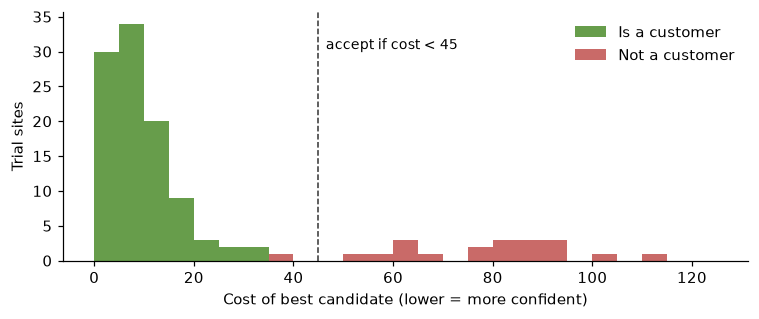

In [8]:
best = cand.sort_values("cost").groupby("trial_id").head(1)
res = trials.merge(best[["trial_id", "c_customer_id", "c_name", "c_lat", "c_lon", "name_score",
                         "address_score", "dist_mi", "cost"]], on="trial_id", how="left")
res["has_true_match"] = res.true_customer_id.notna()

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(0, 130, 5)
ax.hist(res.loc[res.has_true_match, "cost"].dropna(), bins=bins, color="#4c8c2b", alpha=0.85, label="Is a customer")
ax.hist(res.loc[~res.has_true_match, "cost"].dropna(), bins=bins, color="#c0504d", alpha=0.85, label="Not a customer")
THRESHOLD = 45
ax.axvline(THRESHOLD, color="#333", ls="--", lw=1)
ax.text(THRESHOLD + 1.5, ax.get_ylim()[1] * 0.85, f"accept if cost < {THRESHOLD}", fontsize=9)
ax.set(xlabel="Cost of best candidate (lower = more confident)", ylabel="Trial sites")
ax.legend(frameon=False)
plt.tight_layout()

In [9]:
res["matched_id"] = res.c_customer_id.where(res.cost < THRESHOLD)


def outcome(r):
    if r.has_true_match:
        if pd.isna(r.matched_id):
            return "missed"
        return "correct match" if r.matched_id == r.true_customer_id else "wrong match"
    return "correctly unmatched" if pd.isna(r.matched_id) else "false match"


res["outcome"] = res.apply(outcome, axis=1)
summary = res.outcome.value_counts().reindex(
    ["correct match", "wrong match", "missed", "correctly unmatched", "false match"], fill_value=0)
print(f"Accuracy: {(res.outcome.isin(['correct match', 'correctly unmatched'])).mean():.1%}")
summary.to_frame("trial sites")

Accuracy: 99.2%


,trial sites
outcome,
correct match,100
wrong match,0
missed,0
correctly unmatched,19
false match,1


## 6. On the map

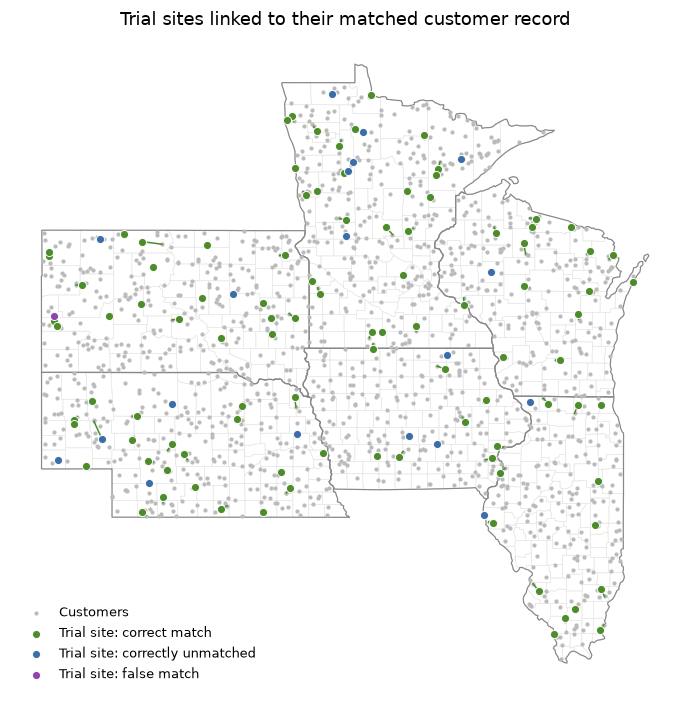

In [10]:
COLORS = {"correct match": "#4c8c2b", "correctly unmatched": "#3b6ea8", "wrong match": "#c0504d",
          "missed": "#e08a1e", "false match": "#8e44ad"}

fig, ax = plt.subplots(figsize=(8.5, 6.5))
counties.boundary.plot(ax=ax, color="#e3e3e3", lw=0.3)
states.boundary.plot(ax=ax, color="#888", lw=0.8)
ax.scatter(customers.lon, customers.lat, s=3, color="#bbbbbb", label="Customers", zorder=2)

linked = res[res.matched_id.notna()]
for _, r in linked.iterrows():
    ax.plot([r.longitude, r.c_lon], [r.latitude, r.c_lat], color=COLORS[r.outcome], lw=1, zorder=3)
for name, grp in res.groupby("outcome"):
    ax.scatter(grp.longitude, grp.latitude, s=28, color=COLORS[name], edgecolor="white", lw=0.6,
               label=f"Trial site: {name}", zorder=4)
ax.set_axis_off()
ax.set_title("Trial sites linked to their matched customer record")
ax.legend(loc="lower left", frameon=False, fontsize=8.5)
plt.tight_layout()

## 7. The hard cases

The one error is the classic failure: a non-customer who shares a common surname with a customer
farming a few miles away. The near misses among the correctly unmatched rows are similar. Real records are
messier than this simulation, and in production a few percent of matches still needed a human look. The
ranked candidate list made that review fast.

In [11]:
show = ["grower_name", "c_name", "name_score", "address_score", "dist_mi", "cost", "outcome"]
order = {"wrong match": 0, "false match": 1, "missed": 2, "correctly unmatched": 3}
hard = res[res.outcome != "correct match"].sort_values("outcome", key=lambda s: s.map(order))
hard[show].round(1).head(12)

,grower_name,c_name,name_score,address_score,dist_mi,cost,outcome
16,Kevin Anderson,PAUL ANDERSON,91.4,37.0,3.6,39.4,false match
3,Wayne Hartman,WAYNE LUND,63.8,24.0,58.7,114.8,correctly unmatched
14,Laura Bauer,BAUER FAMILY FARMS,66.2,83.3,40.5,65.7,correctly unmatched
17,Steven Hansen,KENNETH HANSEN,86.7,24.0,37.7,82.4,correctly unmatched
20,Gary Schmidt,JAMES SCHMIDT,92.8,53.8,48.8,75.5,correctly unmatched
23,Charles Schultz,ANDREW SCHULTZ,95.9,61.5,66.7,88.0,correctly unmatched
29,Richard Lund,RICHARD MEYER,68.8,46.2,19.2,61.7,correctly unmatched
40,Jennifer Richter,RICHTER FARMS LLC,65.4,14.8,33.4,93.3,correctly unmatched
43,Jennifer Richter,JENNIFER KLEIN,69.7,48.3,22.8,63.8,correctly unmatched
55,Paul Sorensen,ROBERT SORENSEN,90.2,61.5,54.3,78.4,correctly unmatched


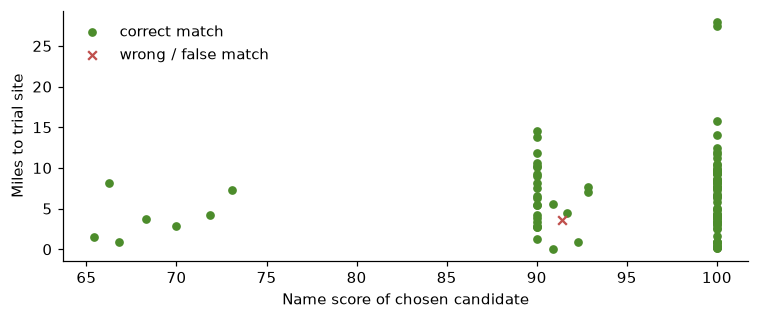

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
ok = res[res.outcome == "correct match"]
ax.scatter(ok.name_score, ok.dist_mi, s=22, color="#4c8c2b", label="correct match")
bad = res[res.outcome.isin(["wrong match", "false match"])]
ax.scatter(bad.name_score, bad.dist_mi, s=32, color="#c0504d", marker="x", label="wrong / false match")
ax.set(xlabel="Name score of chosen candidate", ylabel="Miles to trial site")
ax.legend(frameon=False)
plt.tight_layout()

## Takeaways

- **Combine weak signals.** No single signal is enough on its own: names repeat, addresses are often blank,
  and trial fields are miles from the farmstead. Blending all three into one cost works far better.
- **Clean with word boundaries.** Stripping filler words is essential, but naive substring removal corrupts real names.
- **Don't penalize missing data.** A blank address isn't evidence against a match. Averaging only the
  scores that exist took this from 81% to 99% accuracy here.
- **Allow "no match".** A threshold on the best candidate's cost keeps non-customers from being forced onto
  the nearest look-alike.
- **Simulate to measure.** With known true matches, the threshold and weights can be tuned against an actual
  accuracy number instead of eyeballing.

*Original: PySpark UDFs, Spark window functions, geopy, RapidFuzz on Databricks. This version: pandas,
GeoPandas, RapidFuzz, with simulated growers.*